In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("loan_approval_dataset.csv")

In [3]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,NotGraduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,NotGraduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [5]:
# Check for missing values
df.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [6]:
df.shape

(4269, 13)

In [7]:
print("Correlation Coefficient is:", df['income_annum'].corr(df['loan_amount']))

Correlation Coefficient is: 0.9274699109871488


In [8]:
# X is independent and y is Dependent
X = df[['income_annum']]
y = df['loan_amount']

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
# gives shape of training and testing Data
X_train.shape, X_test.shape

((3415, 1), (854, 1))

In [11]:
from sklearn.linear_model import LinearRegression

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.99]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['income_annum']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.066e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [13]:
# Display coefficient and intercept
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 2.993563764192199
Intercept: 20661.21798559837


In [14]:
y_pred = model.predict(X_test)

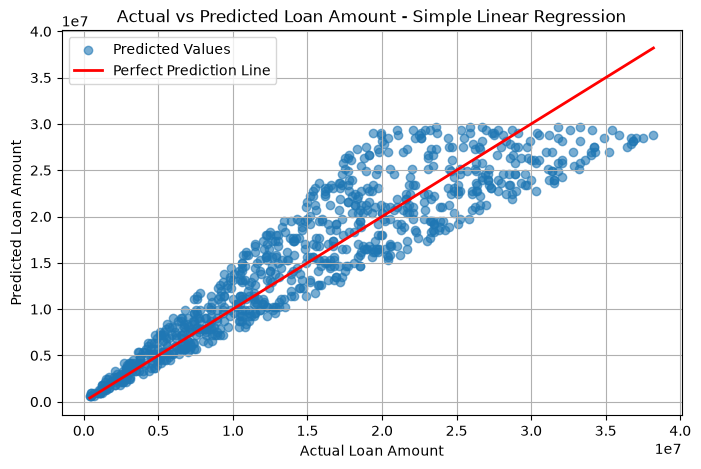

In [15]:
# Actual vs Predicted Loan Amount
plt.figure(figsize=(8, 5))
# Actual values vs predicted values
plt.scatter(y_test, y_pred, alpha=0.6, label='Predicted Values')
# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2,
    label='Perfect Prediction Line'
)
plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")
plt.title("Actual vs Predicted Loan Amount - Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
comparison = pd.DataFrame({'Actual Loan Amount': y_test.values,'Predicted Loan Amount': y_pred})
comparison.head(10)

,Actual Loan Amount,Predicted Loan Amount
0,19700000,1.618591e+07
1,14000000,1.768269e+07
2,19900000,2.875887e+07
3,23400000,1.858076e+07
4,14100000,1.738333e+07
5,12500000,1.409041e+07
6,13500000,1.019878e+07
7,13700000,1.528784e+07
8,8500000,9.899422e+06
9,6000000,9.001353e+06


In [17]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-Squared (R2):", r2)
print("R-Squared Percentage:", r2 * 100, "%")

Mean Squared Error (MSE): 11891356040419.738
Root Mean Squared Error (RMSE): 3448384.555182287
R-Squared (R2): 0.851700687204373
R-Squared Percentage: 85.1700687204373 %


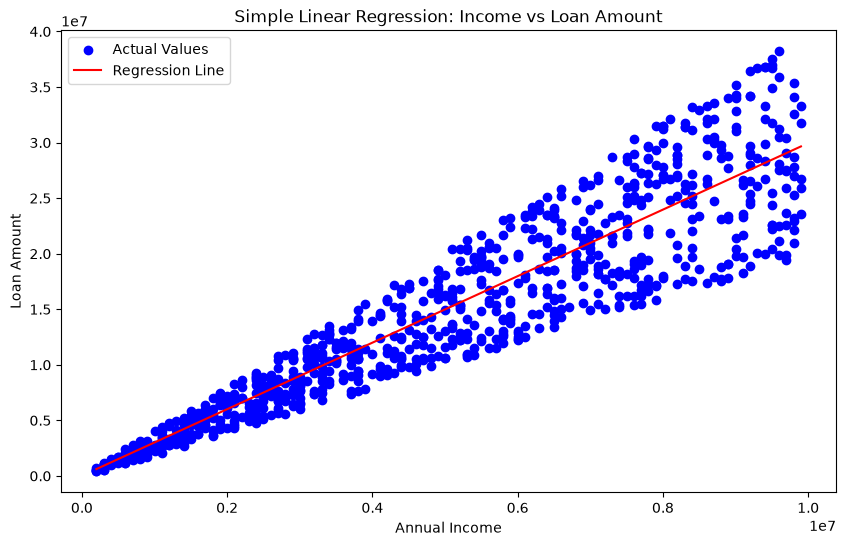

In [18]:
plot_data = pd.DataFrame({
    'income_annum': X_test['income_annum'].values,
    'predicted_loan': y_pred
}).sort_values('income_annum')

plt.figure(figsize=(10, 6))

plt.scatter(X_test['income_annum'], y_test,
            color='blue', label='Actual Values')

plt.plot(plot_data['income_annum'], plot_data['predicted_loan'],
         color='red', label='Regression Line')

plt.xlabel('Annual Income')
plt.ylabel('Loan Amount')
plt.title('Simple Linear Regression: Income vs Loan Amount')

plt.legend()
plt.show()

In [19]:
# Final Model Summary

print("SIMPLE LINEAR REGRESSION - BANK LOAN ANALYSIS")
print("---------------------------------------------")
print("Independent Variable: Annual Income")
print("Dependent Variable: Loan Amount")
print("Algorithm: Linear Regression")
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("R-Squared:", round(r2, 4))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

SIMPLE LINEAR REGRESSION - BANK LOAN ANALYSIS
---------------------------------------------
Independent Variable: Annual Income
Dependent Variable: Loan Amount
Algorithm: Linear Regression
Coefficient: 2.993563764192199
Intercept: 20661.21798559837
R-Squared: 0.8517
MSE: 11891356040419.74
RMSE: 3448384.56


Conclusion

The Simple Linear Regression analysis concludes that annual income is a strong predictor of loan amount, with an R-squared value of 0.8517. This indicates that 85.17% of the variation in loan amount can be explained by annual income. The results demonstrate a strong positive relationship between the two variables, suggesting that applicants with higher annual incomes generally tend to qualify for higher loan amounts.